In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# the folder that contains src/data_loading.py. This works wherever the notebook lives.
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src" / "data_loading.py").exists()
)
sys.path.append(str(PROJECT_ROOT / "src"))
from data_loading import load_data

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

print("Project root:", PROJECT_ROOT)

df = load_data()
df.head()

Project root: /Users/salimalk/credit-card-fraud-detection


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print("Rows and columns:", df.shape)
print("Missing values in total:", df.isna().sum().sum())
df.dtypes.value_counts()

Rows and columns: (284807, 31)
Missing values in total: 0


float64    30
int64       1
Name: count, dtype: int64

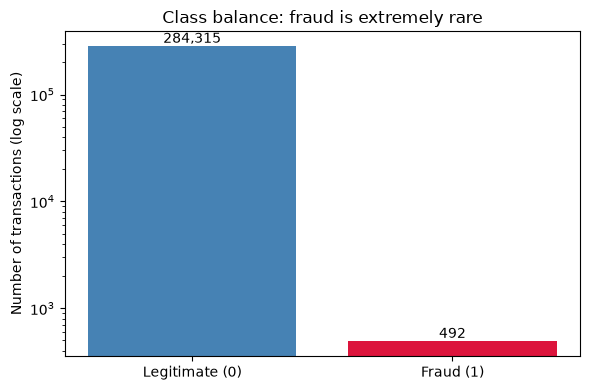

In [4]:
counts = df["Class"].value_counts().sort_index()
labels = ["Legitimate (0)", "Fraud (1)"]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, counts.values, color=["steelblue", "crimson"])

# on a normal scale, the fraud bar would be too small to see
ax.set_yscale("log")
ax.set_ylabel("Number of transactions (log scale)")
ax.set_title("Class balance: fraud is extremely rare")

# writing the exact count above each bar
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:,}",
            ha="center", va="bottom")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "class_balance.png", dpi=150)
plt.show()

In [5]:
print(df.groupby("Class")["Amount"].describe().round(2))

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87


## Observations:

- 0.17% of transactions are fraud, so accuracy alone is misleading.
- data has no missing values.
- the `Amount` column shows how transaction values differ between classes.
